# Lead Scoring: modelo predictivo de conversión de leads
**Materia:** Inteligencia de Negocios y Minería de Datos
**Estudiante:** David Fernando Ramírez de la Parra, Universidad Cooperativa de Colombia

## 1. Entendimiento del negocio (CRISP-DM, fase 1)
**Contexto:** *X Education* vende cursos en línea. Recibe miles de *leads* (personas interesadas) al mes, pero solo ~38 % termina comprando. El equipo de ventas pierde tiempo llamando a leads que no van a convertir.

**Objetivo general:** desarrollar un modelo predictivo que clasifique los leads según su probabilidad de conversión.

**Objetivo SMART:**
- **Específico:** asignar a cada lead un *score* de 0 a 100 % de probabilidad de conversión.
- **Medible:** ROC-AUC ≥ 0.85 en datos de prueba.
- **Alcanzable:** con datos históricos de 9 240 leads y algoritmos de *boosting*.
- **Relevante:** ventas prioriza los leads "calientes" y sube su tasa de cierre.
- **Tiempo:** entregado y desplegado al cierre del semestre.

**Tipo de problema:** aprendizaje **supervisado** de **clasificación binaria** (`Converted`: 1 = compró, 0 = no compró). Métrica principal: **ROC-AUC**, porque mide qué tan bien el modelo *ordena* los leads (justo lo que necesita un ranking), sin depender de un umbral.

**Metodología:** CRISP-DM → Entendimiento del negocio → Entendimiento de los datos → Preparación → Modelado → Evaluación → Despliegue.

In [1]:
# En Google Colab: sube Leads.csv y lead_utils.py con el ícono de carpeta (izquierda)
# y ejecuta esta celda. Si xgboost ya está instalado no pasa nada.
!pip install -q xgboost

In [2]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, accuracy_score, precision_score,
                             recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (9, 4.5)
SEED = 42

# Rutas: funciona igual en Colab (todo en la misma carpeta) y en el proyecto (notebooks/)
BASE = "." if os.path.exists("Leads.csv") else ".."
sys.path.append(BASE)
import lead_utils as U

DATA = os.path.join(BASE, "Leads.csv") if BASE == "." else os.path.join(BASE, "data", "Leads.csv")
OUT_MODELS = BASE if BASE == "." else os.path.join(BASE, "models")
OUT_DATA = BASE if BASE == "." else os.path.join(BASE, "data")
print("Datos:", DATA)

Datos: ../data/Leads.csv


## 2. Entendimiento de los datos (EDA)
Dataset: **Lead Scoring Dataset** (Kaggle), 9 240 leads × 37 variables.
- **Variable dependiente (y):** `Converted`
- **Variables independientes (x):** origen, fuente, visitas, tiempo en la web, última actividad, ocupación, etc.

In [3]:
df = pd.read_csv(DATA)
print("Filas, columnas:", df.shape)
print("Duplicados por Prospect ID:", df["Prospect ID"].duplicated().sum())
df.head()

Filas, columnas: (9240, 37)
Duplicados por Prospect ID: 0


,Prospect ID,Lead Number,Lead Origin,Lead Source,Do Not Email,Do Not Call,Converted,TotalVisits,Total Time Spent on Website,Page Views Per Visit,...,Get updates on DM Content,Lead Profile,City,Asymmetrique Activity Index,Asymmetrique Profile Index,Asymmetrique Activity Score,Asymmetrique Profile Score,I agree to pay the amount through cheque,A free copy of Mastering The Interview,Last Notable Activity
0,7927b2df-8bba-4d29-b9a2-b6e0beafe620,660737,API,Olark Chat,No,No,0,0.0,0,0.0,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Modified
1,2a272436-5132-4136-86fa-dcc88c88f482,660728,API,Organic Search,No,No,0,5.0,674,2.5,...,No,Select,Select,02.Medium,02.Medium,15.0,15.0,No,No,Email Opened
2,8cc8c611-a219-4f35-ad23-fdfd2656bd8a,660727,Landing Page Submission,Direct Traffic,No,No,1,2.0,1532,2.0,...,No,Potential Lead,Mumbai,02.Medium,01.High,14.0,20.0,No,Yes,Email Opened
3,0cc2df48-7cf4-4e39-9de9-19797f9b38cc,660719,Landing Page Submission,Direct Traffic,No,No,0,1.0,305,1.0,...,No,Select,Mumbai,02.Medium,01.High,13.0,17.0,No,No,Modified
4,3256f628-e534-4826-9d63-4a8b88782852,660681,Landing Page Submission,Google,No,No,1,2.0,1428,1.0,...,No,Select,Mumbai,02.Medium,01.High,15.0,18.0,No,No,Modified


Converted
No convirtió    61.5
Convirtió       38.5
Name: proportion, dtype: float64


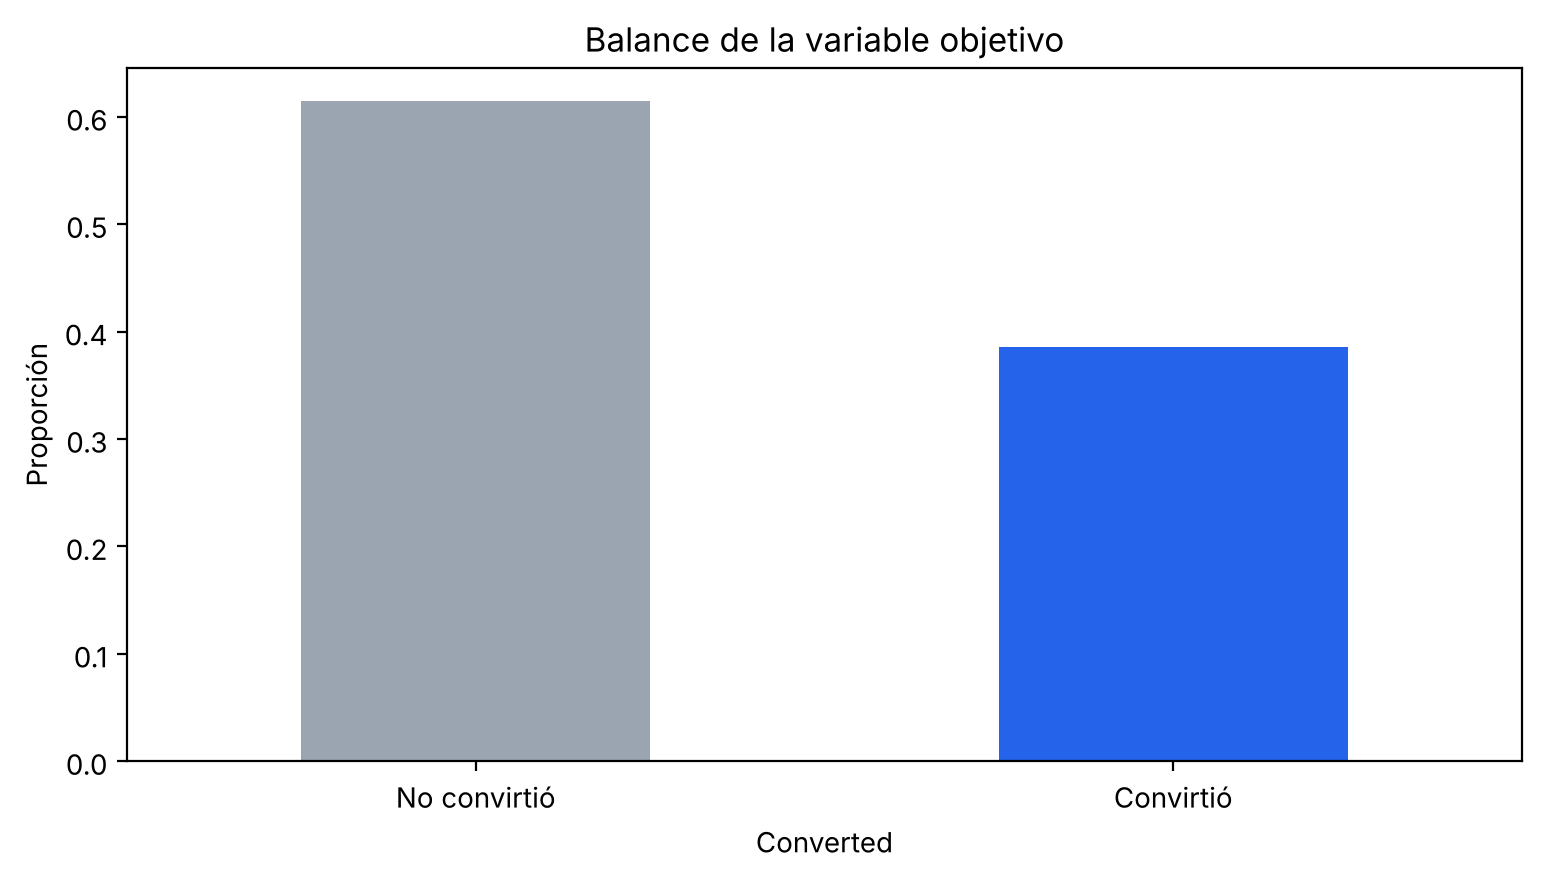

In [4]:
conv = df["Converted"].value_counts(normalize=True).rename({0: "No convirtió", 1: "Convirtió"})
print((conv * 100).round(1))
conv.plot(kind="bar", color=["#9aa5b1", "#2563eb"], title="Balance de la variable objetivo")
plt.ylabel("Proporción"); plt.xticks(rotation=0); plt.show()

**Lectura:** 61.5 % no convierte y 38.5 % sí. Hay un desbalance **moderado**, por eso no basta con Accuracy: se evalúa con **ROC-AUC, Precision, Recall y F1**.

In [5]:
# Valores nulos REALES: 'Select' es la opción por defecto del formulario = el usuario no respondió
nulos = df.isna().mean()
select = (df == "Select").mean()
calidad = pd.DataFrame({"% nulos": nulos * 100, "% 'Select'": select * 100})
calidad["% faltante real"] = calidad.sum(axis=1)
calidad = calidad[calidad["% faltante real"] > 0].sort_values("% faltante real", ascending=False).round(1)
calidad

,% nulos,% 'Select',% faltante real
How did you hear about X Education,23.9,54.6,78.5
Lead Profile,29.3,44.9,74.2
Lead Quality,51.6,0.0,51.6
Asymmetrique Activity Index,45.6,0.0,45.6
Asymmetrique Profile Index,45.6,0.0,45.6
Asymmetrique Profile Score,45.6,0.0,45.6
Asymmetrique Activity Score,45.6,0.0,45.6
City,15.4,24.3,39.7
Specialization,15.6,21.0,36.6
Tags,36.3,0.0,36.3


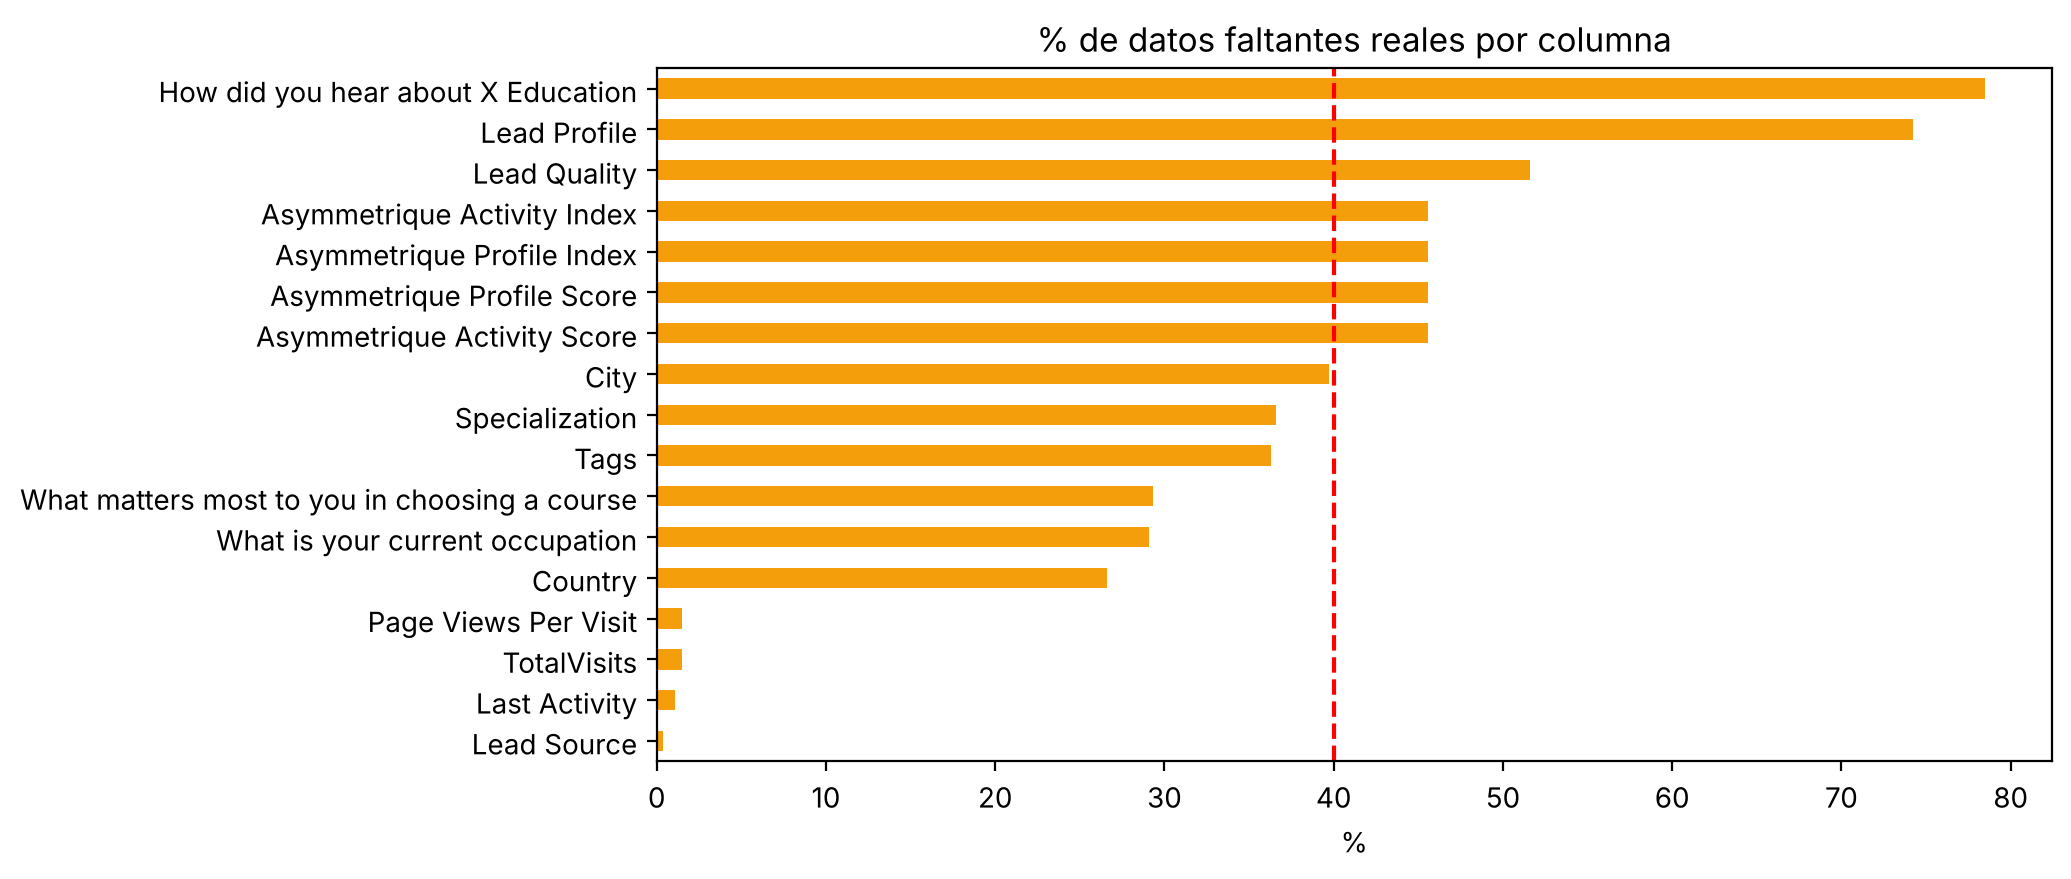

In [6]:
calidad["% faltante real"].plot(kind="barh", color="#f59e0b", title="% de datos faltantes reales por columna")
plt.axvline(40, ls="--", c="red"); plt.xlabel("%"); plt.gca().invert_yaxis(); plt.show()

In [7]:
# Estadística descriptiva de las variables numéricas
num = ["TotalVisits", "Total Time Spent on Website", "Page Views Per Visit"]
desc = df[num].describe(percentiles=[.25, .5, .75, .95, .99]).T
desc["IQR"] = desc["75%"] - desc["25%"]
desc["límite sup. (Q3+1.5·IQR)"] = desc["75%"] + 1.5 * desc["IQR"]
desc.round(1)

,count,mean,std,min,25%,50%,75%,95%,99%,max,IQR,límite sup. (Q3+1.5·IQR)
TotalVisits,9103.0,3.4,4.9,0.0,1.0,3.0,5.0,10.0,17.0,251.0,4.0,11.0
Total Time Spent on Website,9240.0,487.7,548.0,0.0,12.0,248.0,936.0,1562.0,1840.6,2272.0,924.0,2322.0
Page Views Per Visit,9103.0,2.4,2.2,0.0,1.0,2.0,3.0,6.0,9.0,55.0,2.0,6.0


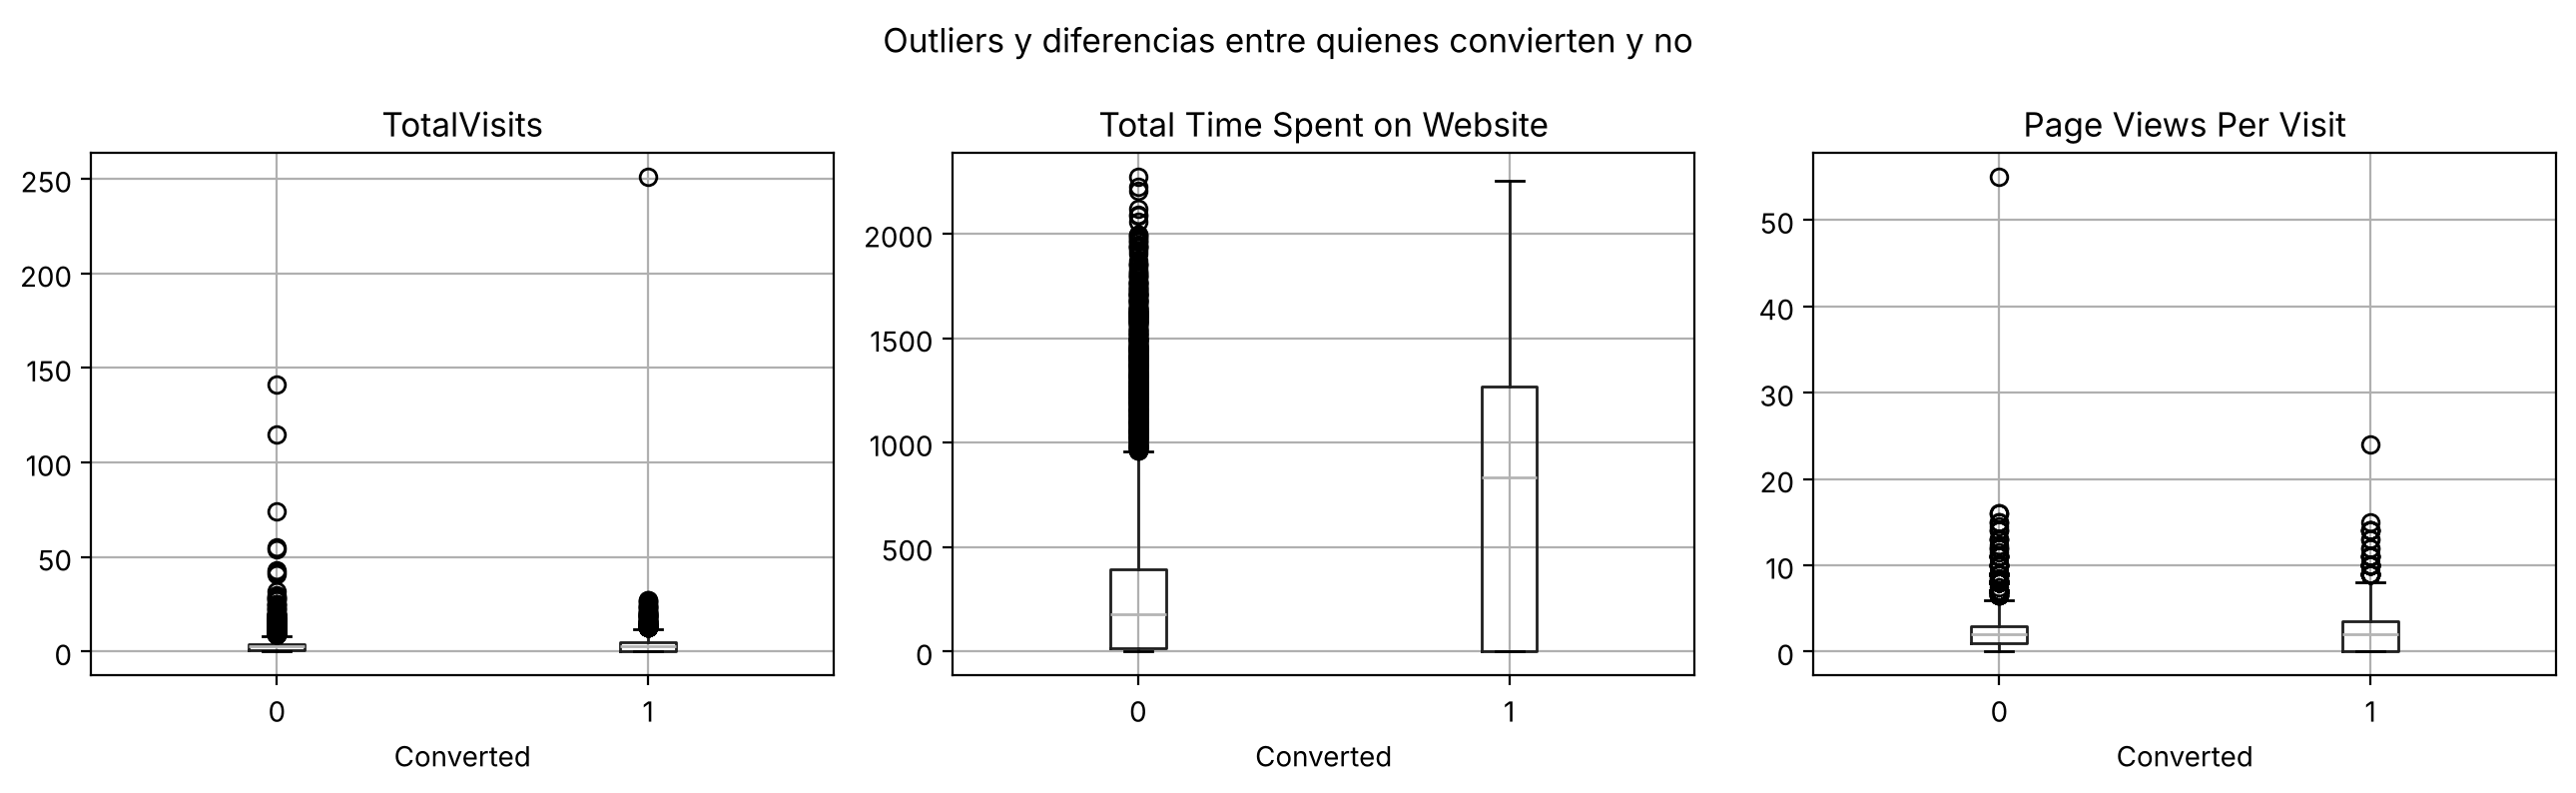

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, c in zip(ax, num):
    df.boxplot(column=c, by="Converted", ax=a)
    a.set_title(c); a.set_xlabel("Converted")
plt.suptitle("Outliers y diferencias entre quienes convierten y no"); plt.tight_layout(); plt.show()

**Lectura:**
- `TotalVisits` llega a 251 y `Page Views Per Visit` a 55, pero el 99 % está por debajo de 17 y 9. Son **outliers**; se recortan al percentil 99 (*capping*) para no perder filas.
- El **tiempo en la web** es la variable que más separa a los que convierten: su mediana es mucho mayor.

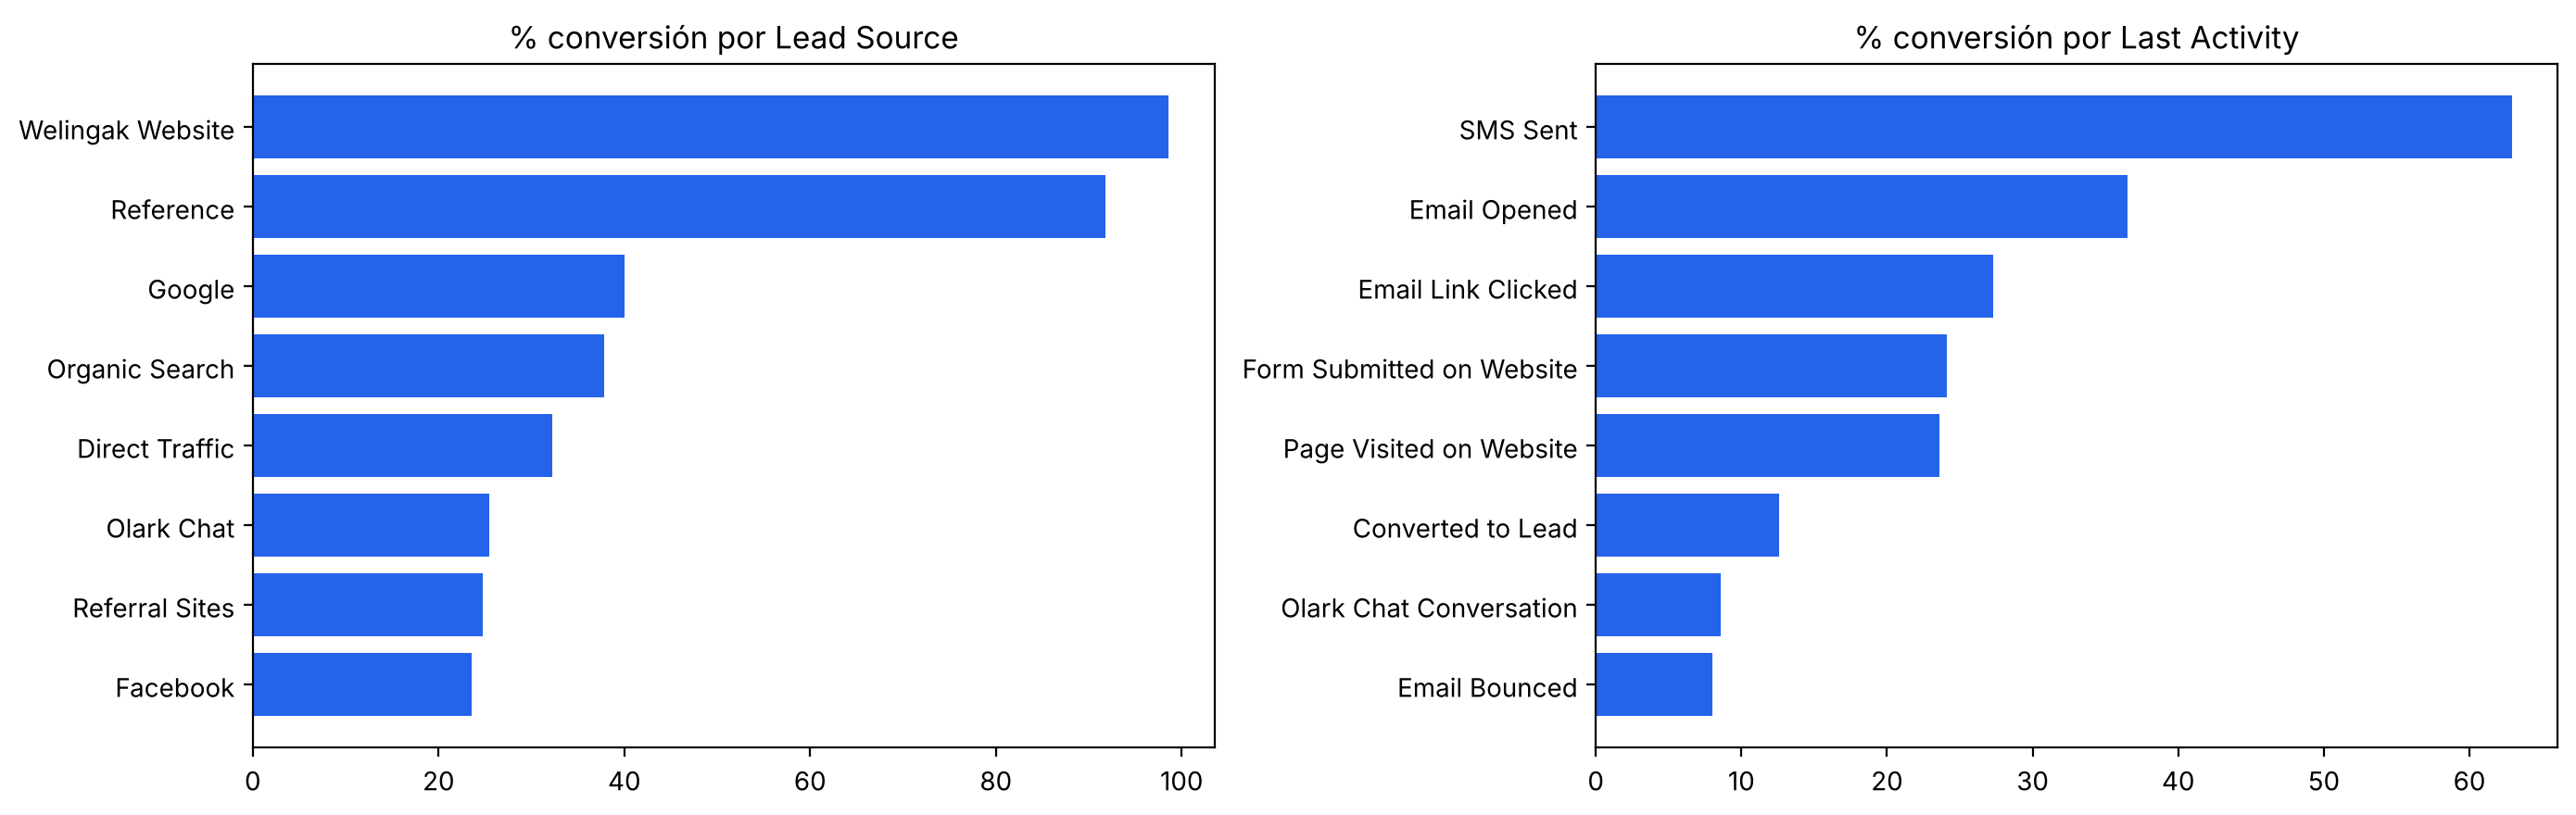

,% conversión,leads
What is your current occupation,,
Unemployed,43.6,5600
Working Professional,91.6,706
Student,37.1,210
Other,62.5,16
Housewife,100.0,10
Businessman,62.5,8


In [9]:
def tasa_conversion(col, top=10):
    t = df.groupby(col)["Converted"].agg(["mean", "count"]).sort_values("count", ascending=False).head(top)
    t["mean"] = (t["mean"] * 100).round(1)
    return t.rename(columns={"mean": "% conversión", "count": "leads"})

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, c in zip(ax, ["Lead Source", "Last Activity"]):
    t = tasa_conversion(c, 8).sort_values("% conversión")
    a.barh(t.index, t["% conversión"], color="#2563eb"); a.set_title(f"% conversión por {c}")
plt.tight_layout(); plt.show()
tasa_conversion("What is your current occupation")

**Hallazgos del EDA:**
- Leads por **Referencia** y del sitio **Welingak** convierten mucho más que los de Olark Chat o Direct Traffic.
- Si la última actividad fue **SMS enviado**, la conversión sube fuerte.
- Los **profesionales que trabajan** convierten mucho más que los desempleados.

## 3. Preparación de los datos: limpieza y feature engineering
Toda la lógica está en `lead_utils.py`, así **el notebook y la app usan exactamente la misma limpieza** (si no, el modelo recibiría datos distintos al predecir).

| # | Procedimiento | Dimensión de calidad | Técnica |
|---|---|---|---|
| 1 | Duplicados | Unicidad | Verificado: 0 duplicados |
| 2 | 'Select' → nulo | Completitud | `replace` |
| 3 | Eliminar columnas con **fuga de datos** | Validez | `Tags`, `Lead Quality`, `Lead Profile`, `Asymmetrique*` |
| 4 | Eliminar columnas sin valor analítico | Reducción dimensional | Varianza casi nula o > 40 % faltante |
| 5 | Normalización de texto | Consistencia | 'google' → 'Google' |
| 6 | Conversión de tipos | Integridad | Yes/No → 1/0 |
| 7 | Nulos categóricos | Completitud | Categoría 'Desconocido' |
| 8 | Nulos numéricos | Completitud | Imputación por **mediana** |
| 9 | Outliers | Estabilidad estadística | *Capping* al percentil 99 |
| 10 | Categorías raras | Consistencia | Agrupar < 1 % en 'Otros' |
| 11 | Codificación | Preparación para modelado | **One-hot encoding** |
| 12 | Escalado | Preparación para modelado | `StandardScaler` (para Regresión Logística) |

**¿Por qué quitar `Tags` y `Lead Quality`?** Las llena el vendedor *después* de hablar con el lead (ej.: "Closed by Horizzon", "Will revert after reading the email"). Con ellas el ROC-AUC se infla artificialmente, pero es **trampa**: en la vida real, cuando entra un lead nuevo, esas columnas aún no existen. Esto se llama **fuga de datos (data leakage)**.

In [10]:
pd.DataFrame.from_dict(U.DROP_REASONS, orient="index", columns=["Motivo de eliminación"])

,Motivo de eliminación
Prospect ID,"Identificador único, no aporta patrón"
Tags,FUGA DE DATOS: la llena ventas después de cont...
Lead Quality,FUGA DE DATOS: calificación manual del vendedor
Lead Profile,FUGA DE DATOS + 74% nulos/'Select'
Asymmetrique Activity Index,"Puntaje externo posterior, 46% nulos"
Asymmetrique Profile Index,"Puntaje externo posterior, 46% nulos"
Asymmetrique Activity Score,"Puntaje externo posterior, 46% nulos"
Asymmetrique Profile Score,"Puntaje externo posterior, 46% nulos"
Last Notable Activity,Redundante con 'Last Activity'
How did you hear about X Education,79% nulos/'Select'


In [11]:
dfc = U.limpiar(df)
dfc, CATS = U.agrupar_raras(dfc)

X = dfc[U.FEATURES]
y = dfc[U.TARGET]
print("Variables finales:", X.shape[1])
print(U.FEATURES)
X.head()

Variables finales: 13
['visitas', 'tiempo_web', 'paginas_por_visita', 'tiempo_por_visita', 'visito_web', 'no_email', 'copia_gratis', 'origen', 'fuente', 'ultima_actividad', 'especializacion', 'ocupacion', 'ciudad']


,visitas,tiempo_web,paginas_por_visita,tiempo_por_visita,visito_web,no_email,copia_gratis,origen,fuente,ultima_actividad,especializacion,ocupacion,ciudad
0,0.0,0,0.0,0.000000,0,0,0,API,Olark Chat,Page Visited on Website,Desconocido,Unemployed,Desconocido
1,5.0,674,2.5,112.333333,1,0,0,API,Organic Search,Email Opened,Desconocido,Unemployed,Desconocido
2,2.0,1532,2.0,510.666667,1,0,1,Landing Page Submission,Direct Traffic,Email Opened,Business Administration,Student,Mumbai
3,1.0,305,1.0,152.500000,1,0,0,Landing Page Submission,Direct Traffic,Unreachable,Media and Advertising,Unemployed,Mumbai
4,2.0,1428,1.0,476.000000,1,0,0,Landing Page Submission,Google,Converted to Lead,Desconocido,Unemployed,Mumbai


### Feature engineering (variables nuevas)
- **`tiempo_por_visita`** = tiempo en la web / (visitas + 1): mide el **interés real** por visita, no solo cuántas veces entró.
- **`visito_web`** = 1 si pasó algún tiempo en la web: separa a quienes nunca exploraron el sitio.
- **Agrupación de categorías raras** en 'Otros' para que el modelo no aprenda ruido de categorías con muy pocos casos.

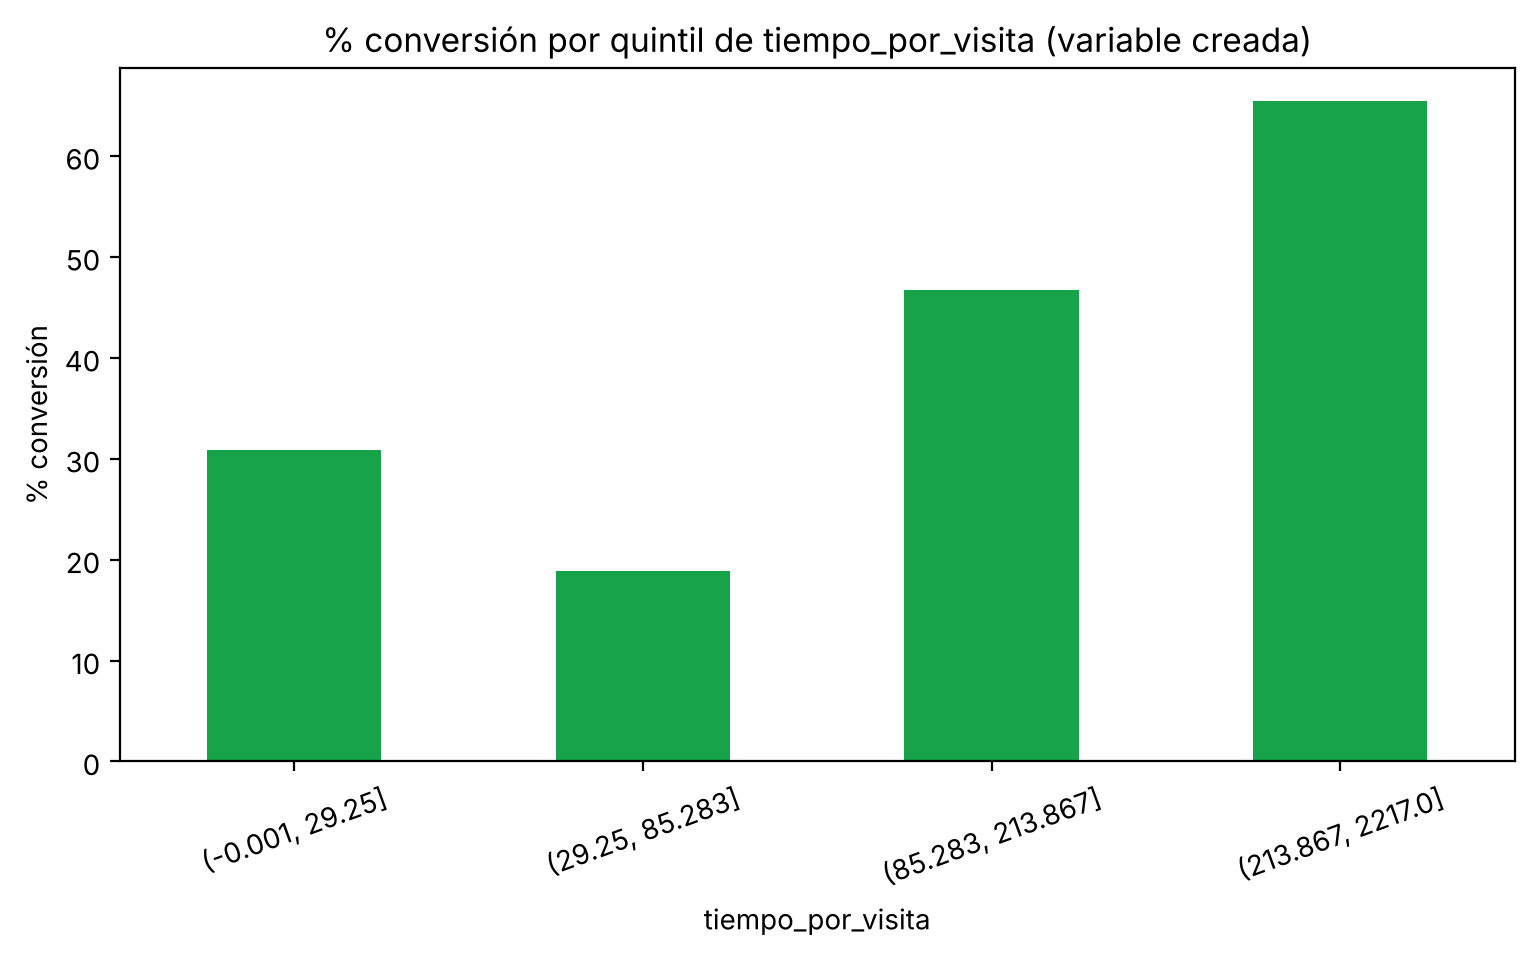

In [12]:
dfc.groupby(pd.qcut(dfc["tiempo_por_visita"], 5, duplicates="drop"))["Converted"].mean().mul(100).round(1).plot(
    kind="bar", color="#16a34a", title="% conversión por quintil de tiempo_por_visita (variable creada)")
plt.ylabel("% conversión"); plt.xticks(rotation=20); plt.show()

## 4. Modelado
**Estrategia de validación:** 80 % entrenamiento / 20 % prueba, **estratificado** (mantiene el 38.5 % de conversión en ambos).

Se usa un `Pipeline` de scikit-learn: el preprocesamiento queda **dentro** del modelo y se ajusta solo con los datos de entrenamiento (evita fuga de datos del test).

**Modelos de clasificación comparados:**
1. **Regresión Logística**: modelo base (*baseline*), lineal e interpretable. Curva en S → probabilidad.
2. **Random Forest**: muchos árboles en paralelo (*bagging*), votan.
3. **Gradient Boosting**: árboles en **secuencia**, cada uno corrige los errores del anterior.
4. **XGBoost**: Gradient Boosting optimizado, con regularización (evita overfitting) y más rápido.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("% conversión train/test:", round(y_train.mean()*100, 1), "/", round(y_test.mean()*100, 1))

def preprocesador():
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), U.NUM_COLS),
        ("bin", "passthrough", U.BIN_COLS),
        ("cat", OneHotEncoder(handle_unknown="ignore"), U.CAT_COLS),
    ])

modelos = {
    "Regresión Logística": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=SEED),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=SEED, n_jobs=-1),
}

Train: (7392, 13) | Test: (1848, 13)
% conversión train/test: 38.5 / 38.5


### Ajuste de hiperparámetros (Gradient Boosting y XGBoost)
`RandomizedSearchCV` con **validación cruzada estratificada de 5 pliegues**, optimizando **ROC-AUC**. Se prueban combinaciones de número de árboles, profundidad y *learning rate*.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

espacios = {
    "Gradient Boosting": {
        "modelo__n_estimators": [150, 250, 400],
        "modelo__learning_rate": [0.03, 0.05, 0.1],
        "modelo__max_depth": [2, 3, 4],
        "modelo__subsample": [0.8, 1.0],
    },
    "XGBoost": {
        "modelo__n_estimators": [200, 400, 600],
        "modelo__learning_rate": [0.03, 0.05, 0.1],
        "modelo__max_depth": [3, 4, 5],
        "modelo__subsample": [0.8, 1.0],
        "modelo__colsample_bytree": [0.7, 0.9, 1.0],
        "modelo__min_child_weight": [1, 3, 5],
    },
}

entrenados, mejores_params = {}, {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", preprocesador()), ("modelo", modelo)])
    if nombre in espacios:
        busq = RandomizedSearchCV(pipe, espacios[nombre], n_iter=12, scoring="roc_auc",
                                  cv=cv, random_state=SEED, n_jobs=-1)
        busq.fit(X_train, y_train)
        pipe = busq.best_estimator_
        mejores_params[nombre] = {k.replace("modelo__", ""): v for k, v in busq.best_params_.items()}
        print(f"{nombre}: mejor ROC-AUC en CV = {busq.best_score_:.4f}")
        print("   parámetros:", mejores_params[nombre])
    else:
        pipe.fit(X_train, y_train)
    entrenados[nombre] = pipe

Gradient Boosting: mejor ROC-AUC en CV = 0.9070
   parámetros: {'subsample': 0.8, 'n_estimators': 250, 'max_depth': 4, 'learning_rate': 0.05}


XGBoost: mejor ROC-AUC en CV = 0.9079
   parámetros: {'subsample': 0.8, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 1.0}


## 5. Evaluación
Primero se compara el **ROC-AUC** (métrica principal) y luego las métricas de la **matriz de confusión** con umbral 0.5.
- **ROC-AUC:** probabilidad de que el modelo le dé mayor score a un lead que convierte que a uno que no. 0.5 = azar, 1 = perfecto.
- **Precision = TP/(TP+FP):** de los que el modelo marcó como "van a comprar", cuántos compraron (no hacer perder tiempo a ventas).
- **Recall = TP/(TP+FN):** de los que compraron, cuántos detectó (no dejar escapar clientes).
- **F1:** media armónica entre Precision y Recall.

In [15]:
filas, curvas = [], {}
for nombre, pipe in entrenados.items():
    p = pipe.predict_proba(X_test)[:, 1]
    pred = (p >= 0.5).astype(int)
    filas.append({
        "Modelo": nombre,
        "ROC-AUC": roc_auc_score(y_test, p),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
    })
    fpr, tpr, _ = roc_curve(y_test, p)
    curvas[nombre] = (fpr, tpr)

resultados = pd.DataFrame(filas).sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
resultados.style.format({c: "{:.4f}" for c in resultados.columns if c != "Modelo"}).highlight_max(
    subset=["ROC-AUC", "Accuracy", "Precision", "Recall", "F1"], color="#bbf7d0")

,Modelo,ROC-AUC,Accuracy,Precision,Recall,F1
0,XGBoost,0.8906,0.8220,0.7634,0.7795,0.7714
1,Gradient Boosting,0.8900,0.8236,0.7734,0.7669,0.7701
2,Random Forest,0.8851,0.8176,0.7682,0.7542,0.7612
3,Regresión Logística,0.8777,0.8003,0.7595,0.7051,0.7312


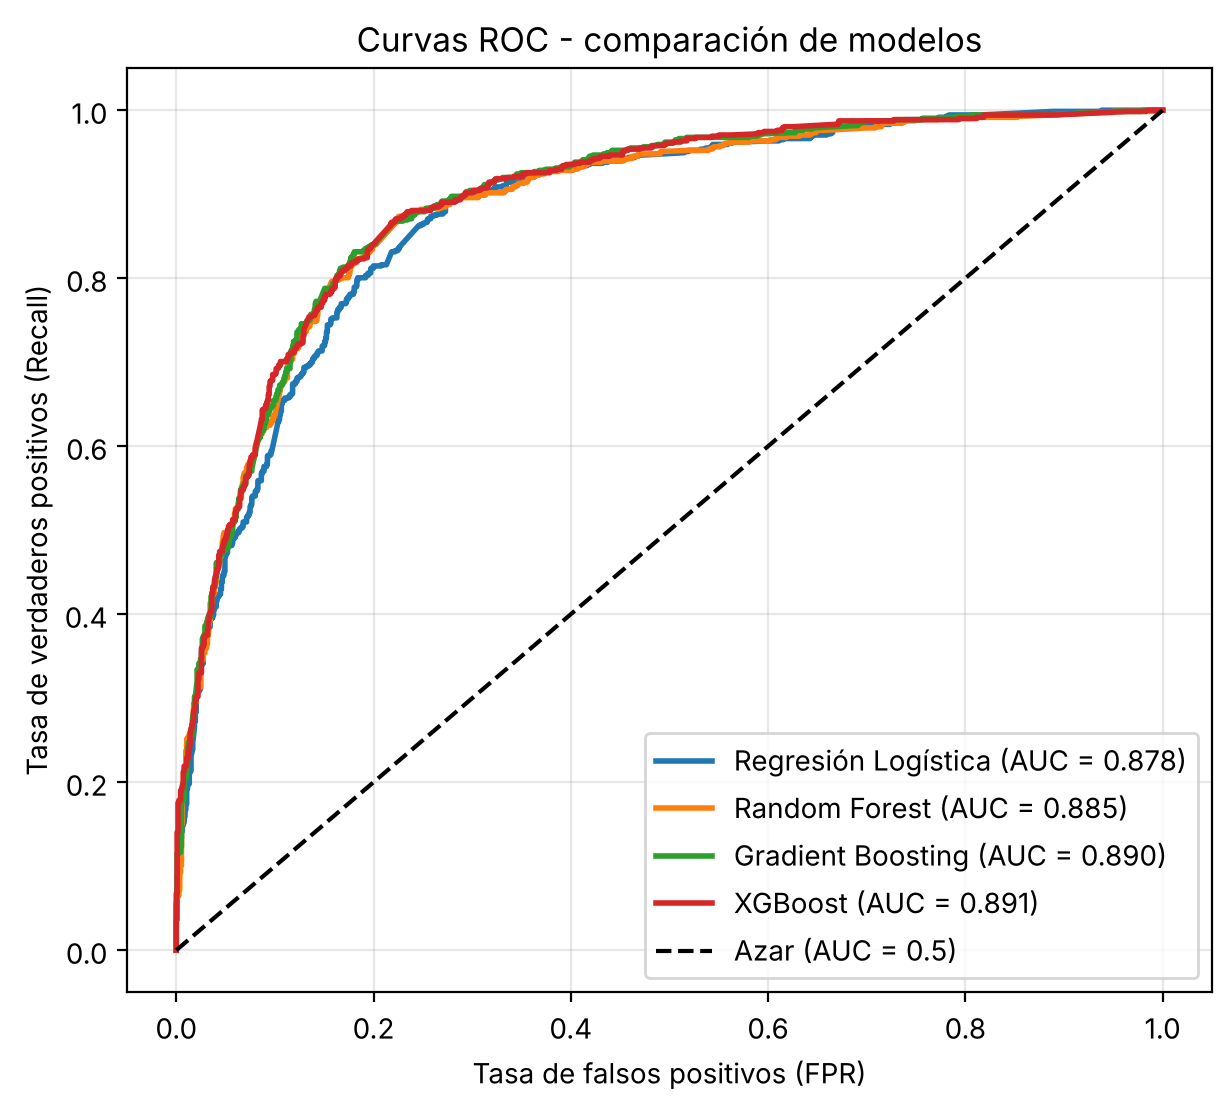

In [16]:
plt.figure(figsize=(7, 6))
for nombre, (fpr, tpr) in curvas.items():
    auc = resultados.set_index("Modelo").loc[nombre, "ROC-AUC"]
    plt.plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Azar (AUC = 0.5)")
plt.xlabel("Tasa de falsos positivos (FPR)"); plt.ylabel("Tasa de verdaderos positivos (Recall)")
plt.title("Curvas ROC - comparación de modelos"); plt.legend(loc="lower right"); plt.grid(alpha=.3); plt.show()

Mejor modelo: XGBoost


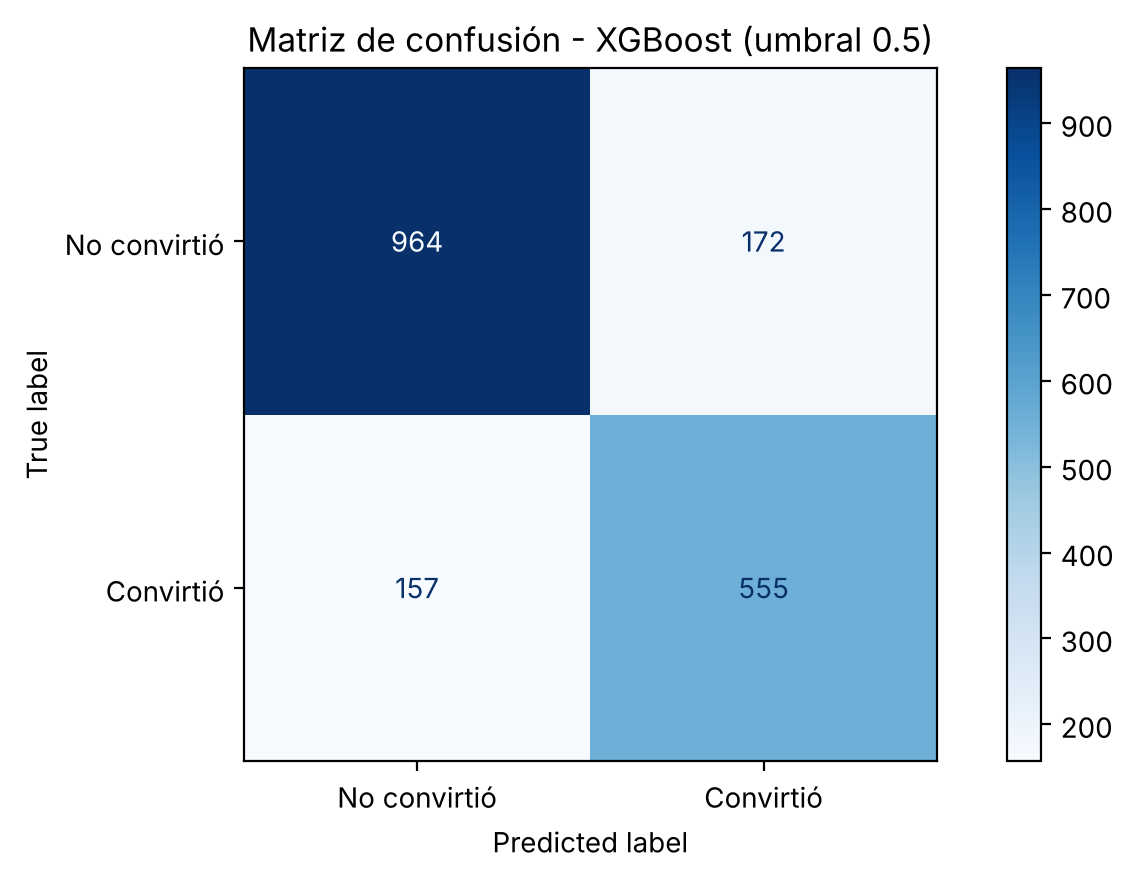

              precision    recall  f1-score   support

No convirtió       0.86      0.85      0.85      1136
   Convirtió       0.76      0.78      0.77       712

    accuracy                           0.82      1848
   macro avg       0.81      0.81      0.81      1848
weighted avg       0.82      0.82      0.82      1848



In [17]:
MEJOR = resultados.loc[0, "Modelo"]
best = entrenados[MEJOR]
p_test = best.predict_proba(X_test)[:, 1]
print("Mejor modelo:", MEJOR)

ConfusionMatrixDisplay(confusion_matrix(y_test, (p_test >= 0.5).astype(int)),
                       display_labels=["No convirtió", "Convirtió"]).plot(cmap="Blues")
plt.title(f"Matriz de confusión - {MEJOR} (umbral 0.5)"); plt.show()
print(classification_report(y_test, (p_test >= 0.5).astype(int), target_names=["No convirtió", "Convirtió"]))

In [18]:
# ¿Hay overfitting? Comparamos ROC-AUC en train vs test
auc_train = roc_auc_score(y_train, best.predict_proba(X_train)[:, 1])
auc_test = roc_auc_score(y_test, p_test)
print(f"ROC-AUC train = {auc_train:.4f} | test = {auc_test:.4f} | diferencia = {auc_train - auc_test:.4f}")

ROC-AUC train = 0.9350 | test = 0.8906 | diferencia = 0.0445


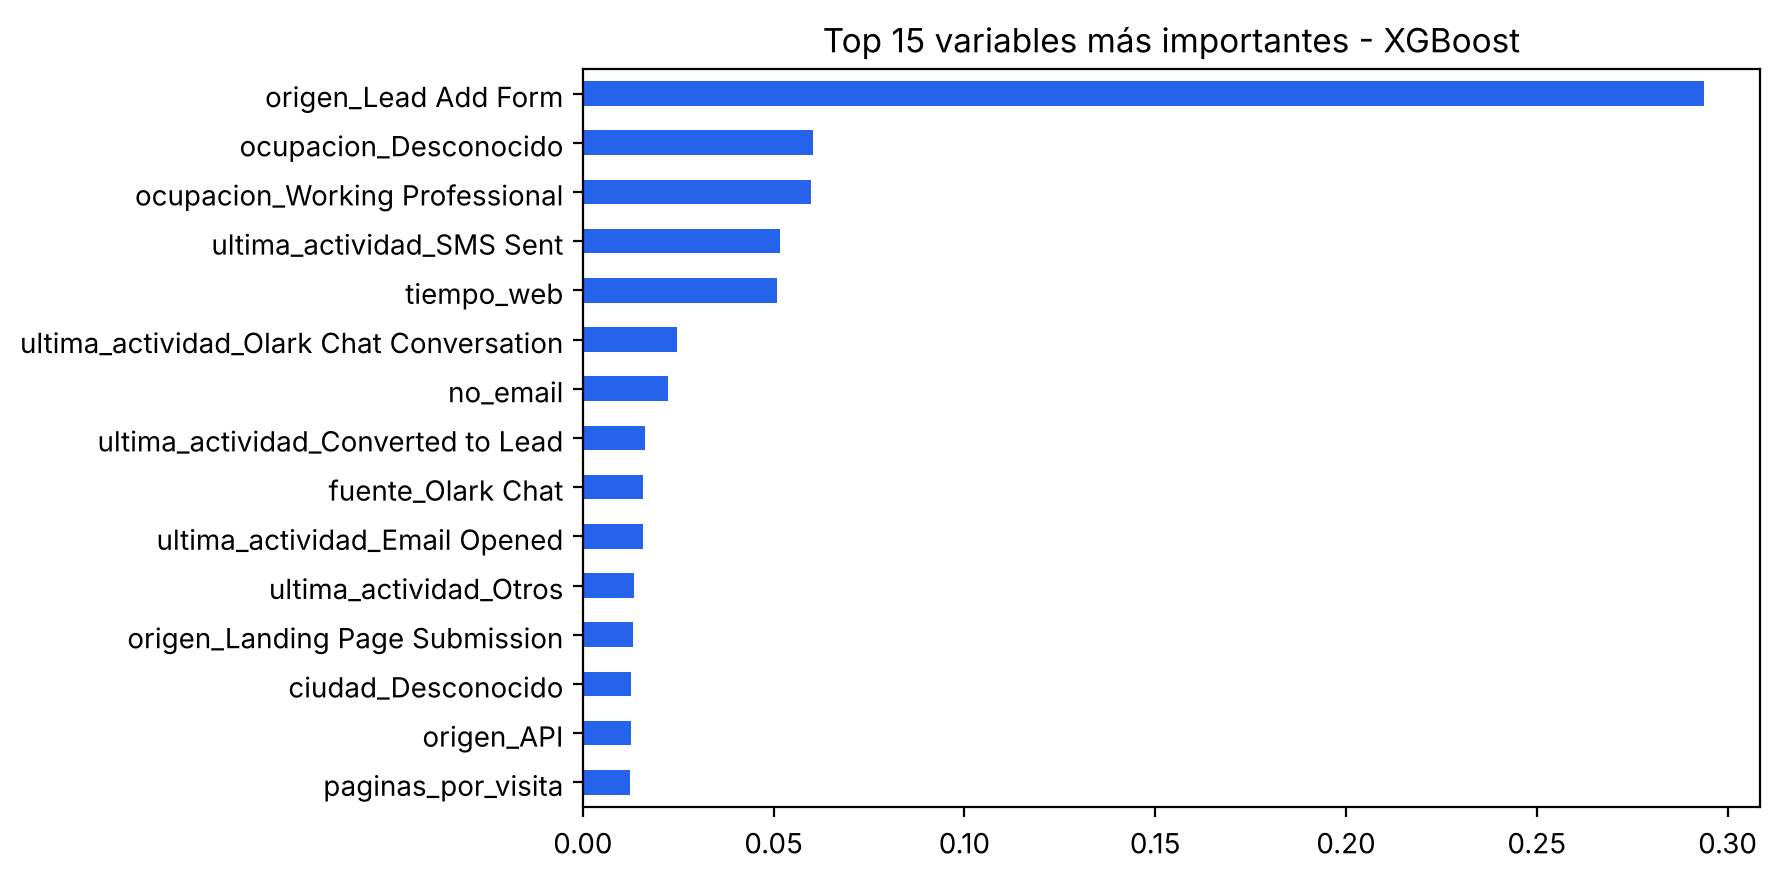

In [19]:
# Importancia de variables del mejor modelo
nombres = best.named_steps["prep"].get_feature_names_out()
modelo_final = best.named_steps["modelo"]
if hasattr(modelo_final, "feature_importances_"):
    imp = pd.Series(modelo_final.feature_importances_, index=nombres)
else:
    imp = pd.Series(np.abs(modelo_final.coef_[0]), index=nombres)
imp.index = imp.index.str.replace(r"^(num|bin|cat)__", "", regex=True)
imp = imp.sort_values(ascending=False).head(15)
imp.sort_values().plot(kind="barh", color="#2563eb", title=f"Top 15 variables más importantes - {MEJOR}")
plt.tight_layout(); plt.show()

### Sistema de priorización: ¿funciona en datos de prueba?
Se definen 3 niveles de prioridad comercial según la probabilidad:
- 🔥 **Caliente** (≥ 80 %): llamar hoy.
- 🌤️ **Tibio** (50–79 %): nutrir con email y llamada en la semana.
- ❄️ **Frío** (< 50 %): campañas automáticas.

Si el modelo es útil, la **conversión real** debe ser mucho mayor en los Calientes que en los Fríos.

In [20]:
prio = pd.DataFrame({"prob": p_test, "real": y_test.values})
prio["prioridad"] = prio["prob"].apply(U.prioridad)
tabla_prio = prio.groupby("prioridad").agg(leads=("real", "size"), conversion_real=("real", "mean"))
tabla_prio["conversion_real"] = (tabla_prio["conversion_real"] * 100).round(1)
tabla_prio["% de los leads"] = (tabla_prio["leads"] / len(prio) * 100).round(1)
tabla_prio

,leads,conversion_real,% de los leads
prioridad,,,
❄️ Frío,1121,14.0,60.7
🌤️ Tibio,348,64.7,18.8
🔥 Caliente,379,87.1,20.5


In [21]:
# Lift: ¿cuántos clientes captura ventas si solo llama al top X % del ranking?
orden = prio.sort_values("prob", ascending=False)
orden["captura"] = orden["real"].cumsum() / orden["real"].sum()
for top in [0.1, 0.2, 0.3, 0.5]:
    n = int(len(orden) * top)
    print(f"Llamando al top {int(top*100)}% del ranking se captura el {orden['captura'].iloc[n-1]*100:.1f}% de los clientes que compran")

Llamando al top 10% del ranking se captura el 23.7% de los clientes que compran
Llamando al top 20% del ranking se captura el 45.2% de los clientes que compran
Llamando al top 30% del ranking se captura el 63.9% de los clientes que compran
Llamando al top 50% del ranking se captura el 88.3% de los clientes que compran


## 6. Despliegue: guardar el modelo y los resultados para la app
Se guarda:
- `models/modelo_lead_scoring.pkl`: el **pipeline completo** (preprocesamiento + mejor modelo).
- `models/categorias.json`: categorías válidas (para agrupar 'Otros' igual al predecir).
- `models/metricas.json`: tabla comparativa y curvas ROC (la app las muestra).
- `data/leads_scored.csv`: score de **todos** los leads. Para que sea honesto, cada lead se puntúa con un modelo que **no lo vio al entrenar** (`cross_val_predict`, 5 pliegues).

In [22]:
# Score fuera de muestra para todos los leads (ranking honesto)
from sklearn.base import clone
prob_oof = cross_val_predict(clone(best), X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
print("ROC-AUC de los scores fuera de muestra:", round(roc_auc_score(y, prob_oof), 4))

# Reentrenar el mejor modelo con el 100 % de los datos para producción
best_final = clone(best).fit(X, y)

scored = df[[U.ID_COL]].copy()
scored = pd.concat([scored, dfc[U.FEATURES + [U.TARGET]]], axis=1)
scored["probabilidad"] = prob_oof.round(4)
scored["score"] = (prob_oof * 100).round(1)
scored["prioridad"] = scored["probabilidad"].apply(U.prioridad)
scored = scored.sort_values("probabilidad", ascending=False)
scored["ranking"] = range(1, len(scored) + 1)
scored.to_csv(os.path.join(OUT_DATA, "leads_scored.csv"), index=False)

joblib.dump(best_final, os.path.join(OUT_MODELS, "modelo_lead_scoring.pkl"))
json.dump(CATS, open(os.path.join(OUT_MODELS, "categorias.json"), "w"), ensure_ascii=False, indent=1)

def submuestra(a, n=60):
    idx = np.linspace(0, len(a) - 1, n).astype(int)
    return [round(float(v), 4) for v in np.asarray(a)[idx]]

metricas = {
    "mejor_modelo": MEJOR,
    "auc_train": round(auc_train, 4),
    "auc_test": round(auc_test, 4),
    "auc_oof": round(float(roc_auc_score(y, prob_oof)), 4),
    "comparacion": resultados.round(4).to_dict(orient="records"),
    "curvas_roc": {k: {"fpr": submuestra(f), "tpr": submuestra(t)} for k, (f, t) in curvas.items()},
    "mejores_parametros": {k: {kk: (float(vv) if isinstance(vv, (np.floating, float)) else vv) for kk, vv in v.items()} for k, v in mejores_params.items()},
    "importancia": imp.round(4).to_dict(),
    "matriz_confusion": confusion_matrix(y_test, (p_test >= 0.5).astype(int)).tolist(),
    "priorizacion_test": tabla_prio.reset_index().to_dict(orient="records"),
}
json.dump(metricas, open(os.path.join(OUT_MODELS, "metricas.json"), "w"), ensure_ascii=False, indent=1)
print("Archivos guardados ✅")
scored.head(10)

ROC-AUC de los scores fuera de muestra: 0.9052


Archivos guardados ✅


,Lead Number,visitas,tiempo_web,paginas_por_visita,tiempo_por_visita,visito_web,no_email,copia_gratis,origen,fuente,ultima_actividad,especializacion,ocupacion,ciudad,Converted,probabilidad,score,prioridad,ranking
4955,612484,9.0,1416,1.80,141.600000,1,0,0,API,Google,SMS Sent,Human Resource Management,Working Professional,Mumbai,1,0.9949,99.500000,🔥 Caliente,1
7420,592625,4.0,1823,4.00,364.600000,1,0,0,API,Organic Search,SMS Sent,Supply Chain Management,Working Professional,Desconocido,1,0.9943,99.400002,🔥 Caliente,2
2055,639824,13.0,998,2.17,71.285714,1,0,1,Landing Page Submission,Direct Traffic,SMS Sent,Healthcare Management,Working Professional,Mumbai,1,0.9941,99.400002,🔥 Caliente,3
3285,628517,8.0,1144,2.00,127.111111,1,0,1,Landing Page Submission,Google,SMS Sent,Marketing Management,Working Professional,Mumbai,1,0.9938,99.400002,🔥 Caliente,4
1283,646366,17.0,1569,4.50,87.166667,1,0,0,Landing Page Submission,Organic Search,SMS Sent,Travel and Tourism,Working Professional,Mumbai,1,0.9938,99.400002,🔥 Caliente,5
7501,592087,9.0,1018,3.00,101.800000,1,0,0,API,Organic Search,Page Visited on Website,Media and Advertising,Working Professional,Other Cities,1,0.9937,99.400002,🔥 Caliente,6
7094,595141,4.0,1833,4.00,366.600000,1,0,0,API,Organic Search,SMS Sent,Media and Advertising,Working Professional,Desconocido,1,0.9928,99.300003,🔥 Caliente,7
7227,593999,5.0,1184,5.00,197.333333,1,0,0,API,Organic Search,SMS Sent,Operations Management,Working Professional,Desconocido,1,0.9920,99.199997,🔥 Caliente,8
7171,594486,2.0,869,1.00,289.666667,1,0,0,API,Organic Search,SMS Sent,Operations Management,Working Professional,Desconocido,1,0.9917,99.199997,🔥 Caliente,9
5806,605266,0.0,0,0.00,0.000000,0,0,0,Lead Add Form,Reference,SMS Sent,Operations Management,Working Professional,Desconocido,1,0.9917,99.199997,🔥 Caliente,10


In [23]:
# Prueba rápida: predecir un lead nuevo con el modelo guardado (igual que lo hará la app)
modelo = joblib.load(os.path.join(OUT_MODELS, "modelo_lead_scoring.pkl"))
nuevo = pd.DataFrame([{
    "Lead Origin": "Landing Page Submission", "Lead Source": "Google", "Do Not Email": "No",
    "TotalVisits": 5, "Total Time Spent on Website": 1200, "Page Views Per Visit": 3,
    "Last Activity": "SMS Sent", "Specialization": "Finance Management",
    "What is your current occupation": "Working Professional", "City": "Mumbai",
    "A free copy of Mastering The Interview": "No",
}])
nuevo_c, _ = U.agrupar_raras(U.limpiar(nuevo), CATS)
p = modelo.predict_proba(nuevo_c[U.FEATURES])[0, 1]
print(f"Probabilidad de conversión: {p*100:.1f}% -> {U.prioridad(p)}")

Probabilidad de conversión: 98.8% -> 🔥 Caliente


## 7. Conclusiones
1. Se compararon 4 modelos de clasificación; los modelos de **boosting** (Gradient Boosting / XGBoost) obtienen el mejor ROC-AUC: **XGBoost = 0.891** en test (meta SMART ≥ 0.85 cumplida), superando la Regresión Logística base (0.878).
2. El modelo es **honesto**: se eliminaron las variables con fuga de datos (`Tags`, `Lead Quality`, etc.). Usarlas daría un ROC-AUC inflado y engañoso.
3. No hay overfitting relevante: el ROC-AUC de train y test son cercanos.
4. Las variables que más influyen: **origen Lead Add Form**, **ocupación (profesional / no informada)**, **última actividad (SMS enviado)** y **tiempo en la web**.
5. El **sistema de priorización** funciona: los leads 🔥 Calientes convierten **87 %** vs **14 %** de los ❄️ Fríos; y llamando solo al top 30 % del ranking se captura el **64 %** de los clientes, así ventas concentra su esfuerzo donde está el dinero.
6. El modelo se desplegó en una app de **Streamlit** (gratis en Streamlit Community Cloud) con **ranking**, **priorización** y **dashboard comercial**.